# Learning only the contact-rich phase vs whole trajectories
### Does a policy that learns only the final contact-rich manipulation, with a VLM + planned reach getting there, generalize better than a whole-trajectory policy trained on the same demos?

**Status (2026-10-31).** Phase 0 is complete: the environment, the datasets, contact-phase segmentation, and a DROID-style segmenter validated against ground truth. The training grid for the first seed has run, and the whole-trajectory results are final. The composed-method evaluations (our policy and controls C1/C2) have been **withheld**: the harness that executes them is still being debugged (§5). The plan with all design decisions is in `docs/PLAN_contact_segment_vs_whole.md`.

In [1]:
import json, os, glob, math, collections
import numpy as np
from IPython.display import display, Markdown, Image, Video
ROOT = os.path.abspath('..'); RUNS = f'{ROOT}/runs/mimicgen'; DEMO = f'{ROOT}/demo/mimicgen'
def wilson(k, n, z=1.96):
    if n == 0: return (float('nan'),) * 2
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d; h = z*math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d; return c - h, c + h
def fmt(R):
    if not R: return '–'
    k, n = sum(r['success'] for r in R), len(R); lo, hi = wilson(k, n); return f"{100*k/n:.0f}% [{100*lo:.0f}–{100*hi:.0f}]"
def table(rows, header):
    out = '| ' + ' | '.join(header) + ' |\n|' + '---|' * len(header) + '\n'
    for r in rows: out += '| ' + ' | '.join(str(x) for x in r) + ' |\n'
    display(Markdown(out))
def load(p): return json.load(open(p)) if os.path.exists(p) else []
TASKS = ['square', 'threading', 'coffee', 'three_piece_assembly', 'mug_cleanup']

---
## 1. Question and positioning

**Hypotheses.**
* **H1:** a contact-segment policy with egocentric inputs, composed with VLM-guided reaching, generalizes better than a whole-trajectory policy trained on the same demos with the same network and budget.
* **H2:** in distribution they are on par.
* **H3:** the gain comes from modelling only the contact phase's variance, not merely from starting near the object. Control C1 (the whole-trajectory policy started at the same handoff) tests this.

**Closest prior work.**
* **HITL-TAMP** (Mandlekar et al., CoRL 2023): TAMP handles free space, and people teleoperate only contact-rich segments. Policies trained on those segments beat full-demo training.
* **SkillMimicGen** (Garrett et al., 2024): learned contact-rich skills, connected by motion planning.

Both assume known object models and poses, and both report mainly in-distribution success and data efficiency.

**What is new here:**
1. open-world VLM grounding from RGB-D + language instead of TAMP's object knowledge;
2. systematic generalization along standard shift axes;
3. segment-only vs whole-trajectory fine-tuning of pretrained VLAs, up to real DROID data;
4. the C1 control and egocentric inputs, which explain *why* any gain appears.

---
## 2. Setup: MimicGen, a standard contact-rich benchmark with built-in generalization splits

| | |
|---|---|
| Tasks | Square (nut insertion), Threading (needle), Coffee (pod insertion + lid), Three-Piece Assembly, Mug Cleanup (drawer + mug) |
| Data | 1000 MimicGen demos per task and variant; 84 px external + wrist images; OSC_POSE delta actions at 20 Hz |
| Generalization | train on **D0**, test on **D0 / D1 / D2**, MimicGen's official reset distributions (D1/D2 place objects over much wider regions) |
| Protocol | MimicGen/robomimic success checks and horizons (400 steps; 500 for Three-Piece Assembly and Mug Cleanup); 100 seeded episodes per variant |
| Stack | robosuite at MimicGen's commit, **MuJoCo 2.3.2** (2.3.7 changes the arm dynamics relative to the data), robomimic d0b37cf; own env on /scratch |
| Network | the LIBERO study's diffusion policy (ResNet18-GN + spatial softmax, 1-D UNet, 16-step chunks, 8 executed), crop 76 px, 100k steps, batch 128, for every policy |

**Policies:**
| | Trained on | Inputs | At test time |
|---|---|---|---|
| **P1 whole-trajectory** | all frames | external + wrist, absolute proprio | runs from reset |
| **P2 contact-segment (ours)** | contact phases only, from 10 steps before first contact | wrist only, position relative to the handoff, subtask id | reach to each subtask's handoff, then P2 |
| **C1** | (= P1) | as P1 | placed at the same handoffs as P2 |
| **C2** | contact phases | external + wrist, absolute proprio | as P2 |

---
## 3. Contact-phase segmentation

Each task is a chain of MimicGen's own object-centric subtasks; for example, Square is grasp the nut, then insert it on the peg.
* Every demo is replayed from its recorded MuJoCo states. Inside each subtask, the **contact phase** starts at the first physical contact between the gripper, or the object it holds, and the subtask's reference object.
* The learned segment starts 10 steps before that contact (the **handoff**) and ends with the subtask.
* Everything before the handoff is free-space motion, done at test time by the VLM-grounded reach.

Below: one demo per task. Blue frames are handled by the VLM and the reach; orange frames are the learned contact phases.

**square**

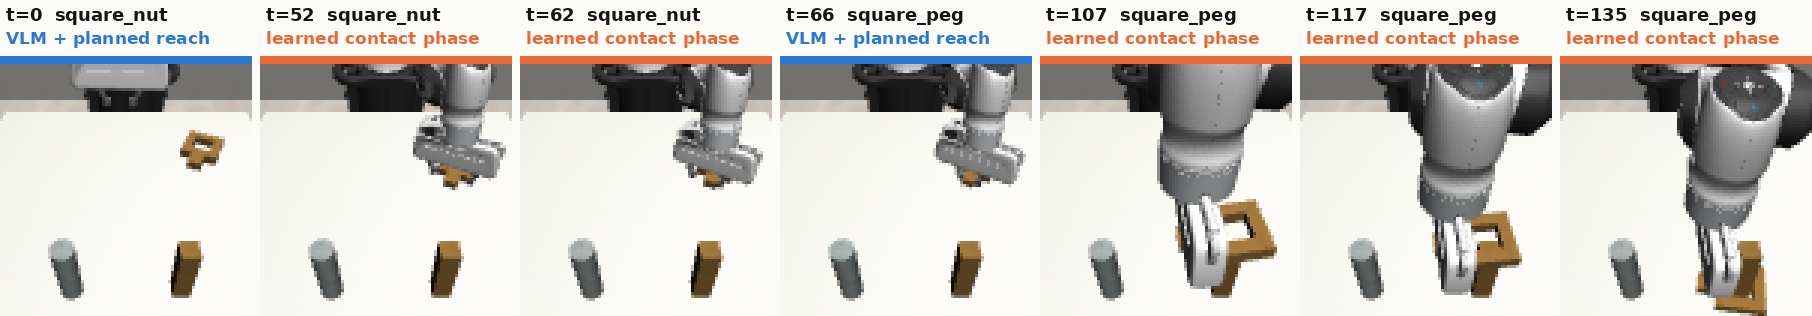

**coffee**

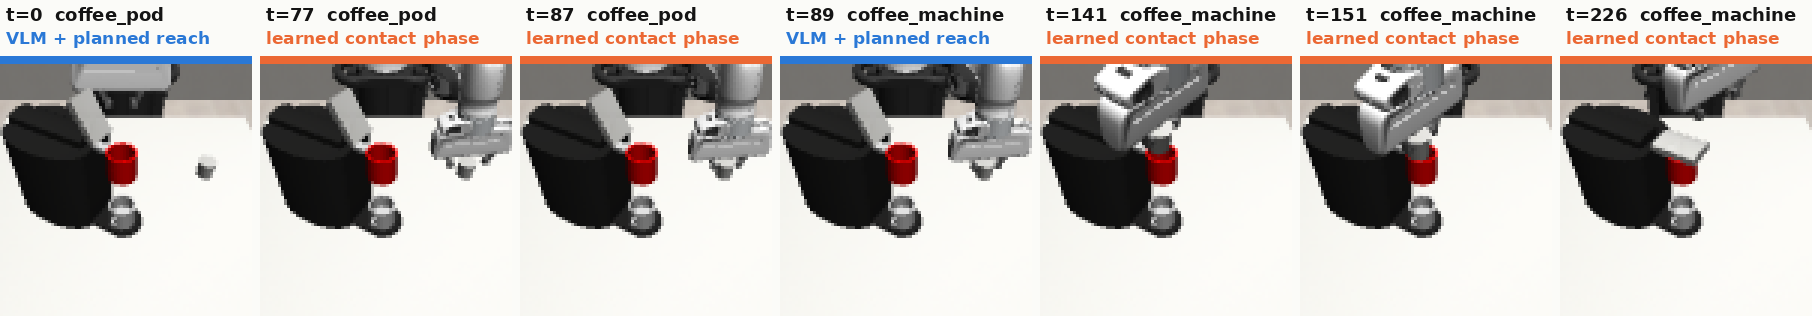

**threading**

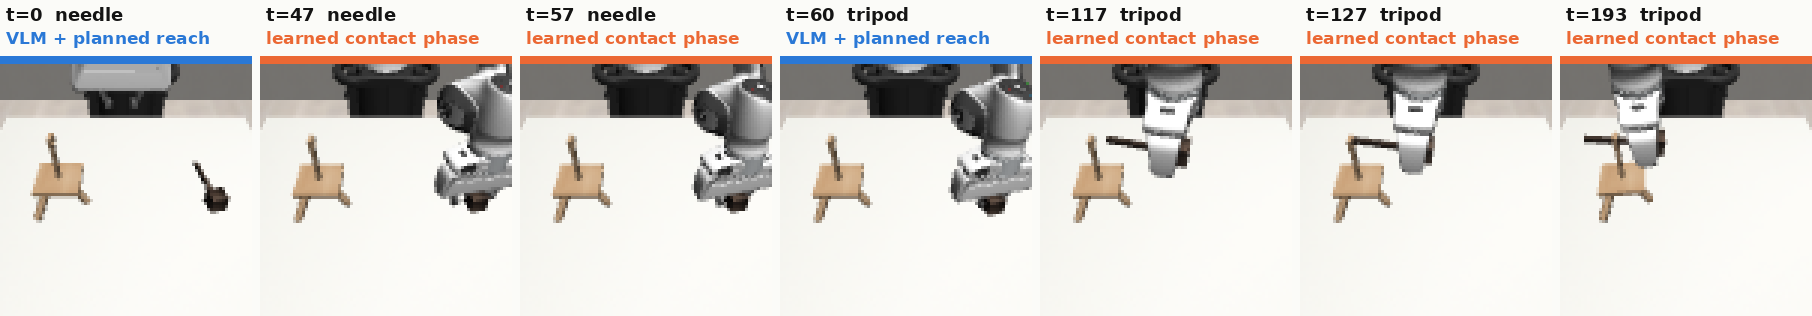

In [2]:
for t in ['square', 'coffee', 'threading']:
    p = f'{DEMO}/contact_phases_{t}.png'
    if os.path.exists(p): display(Markdown(f'**{t}**')); display(Image(p, width=1100))

In [3]:
ST = load(f'{RUNS}/segment_stats.json')
rows = []
for name, st in ST.items():
    for s in st['subtasks']:
        rows.append([name, f"{s['ref']} ({s['signal'] or 'final'})", f"{s['contact_found']}/{st['n_demos']}", f"{s['contact_to_end_median']:.0f}", f"{s['subtask_len_median']:.0f}"])
    rows.append([name, '**share of frames in learned segments**', '', f"{100*st['segment_frame_share_pre10']:.0f}%", ''])
table(rows, ['Dataset', 'Subtask (reference object)', 'Contact found', 'Contact → end (median steps)', 'Whole subtask (median steps)'])

| Dataset | Subtask (reference object) | Contact found | Contact → end (median steps) | Whole subtask (median steps) |
|---|---|---|---|---|
| coffee_d0 | coffee_pod (grasp) | 1000/1000 | 2 | 74 |
| coffee_d0 | coffee_machine (final) | 1000/1000 | 88 | 147 |
| coffee_d0 | **share of frames in learned segments** |  | 50% |  |
| mug_cleanup_d0 | drawer (open) | 1000/1000 | 60 | 102 |
| mug_cleanup_d0 | object (grasp) | 999/1000 | 35 | 76 |
| mug_cleanup_d0 | drawer (final) | 999/1000 | 84 | 162 |
| mug_cleanup_d0 | **share of frames in learned segments** |  | 64% |  |
| square_d0 | square_nut (grasp) | 1000/1000 | 4 | 67 |
| square_d0 | square_peg (final) | 1000/1000 | 33 | 76 |
| square_d0 | **share of frames in learned segments** |  | 42% |  |
| threading_d0 | needle (grasp) | 1000/1000 | 2 | 72 |
| threading_d0 | tripod (final) | 1000/1000 | 69 | 148 |
| threading_d0 | **share of frames in learned segments** |  | 42% |  |
| three_piece_assembly_d0 | piece_1 (grasp_1) | 1000/1000 | 2 | 71 |
| three_piece_assembly_d0 | base (insert_1) | 1000/1000 | 33 | 85 |
| three_piece_assembly_d0 | piece_2 (grasp_2) | 1000/1000 | 3 | 78 |
| three_piece_assembly_d0 | piece_1 (final) | 998/1000 | 42 | 102 |
| three_piece_assembly_d0 | **share of frames in learned segments** |  | 37% |  |


**A note on the data.** MimicGen's core datasets contain only successful demos. Replaying their stored states does not always reproduce the success check (MimicGen post-processed the datasets for robosuite 1.4), so we keep every demo in which all contacts were found. An early version filtered on the replay check and dropped 214 Mug Cleanup demos; those segment trainings were re-run. The first Square and Coffee segment trainings excluded 2 and 5 demos (< 0.5%).

---
## 4. Can contact be found without simulator contact data? (DROID-style segmentation)

DROID provides only end-effector poses and gripper commands. A heuristic segmenter (`vrg/mg/heuristic_segment.py`) estimates contact onsets from those signals alone:
* a close command marks a grasp;
* the slow-down after transporting a held object marks a placement or insertion;
* a slow-down before any grasp marks a push.

Here it is scored against the ground truth of §3.

In [4]:
rows = []
for name, st in ST.items():
    for k, h in st.get('heuristic', {}).items():
        rows.append([name, k, f"{100*h['found']:.0f}%", f"{h['median_err']:+.0f}", f"{100*h['within10']:.0f}%"])
table(rows, ['Dataset', 'Contact', 'Detected', 'Median error (steps)', 'Within ±10 steps'])

| Dataset | Contact | Detected | Median error (steps) | Within ±10 steps |
|---|---|---|---|---|
| coffee_d0 | 0:coffee_pod (grasp) | 100% | -5 | 100% |
| coffee_d0 | 1:coffee_machine (place) | 100% | -17 | 16% |
| mug_cleanup_d0 | 0:drawer (push) | 100% | +2 | 60% |
| mug_cleanup_d0 | 1:object (grasp) | 99% | +19 | 30% |
| mug_cleanup_d0 | 2:drawer (place) | 99% | -2 | 80% |
| square_d0 | 0:square_nut (grasp) | 94% | -6 | 86% |
| square_d0 | 1:square_peg (place) | 100% | +1 | 90% |
| threading_d0 | 0:needle (grasp) | 100% | -6 | 100% |
| threading_d0 | 1:tripod (place) | 100% | -33 | 12% |
| three_piece_assembly_d0 | 0:piece_1 (grasp) | 100% | -6 | 100% |
| three_piece_assembly_d0 | 1:base (place) | 100% | -9 | 53% |
| three_piece_assembly_d0 | 2:piece_2 (grasp) | 100% | -5 | 96% |
| three_piece_assembly_d0 | 3:piece_1 (place) | 100% | -8 | 51% |


**Reading.**
* **Grasps** are found reliably: within ±10 steps in 86–100% of demos, with a fixed bias of about 5–6 steps (the close command precedes finger contact), which can be subtracted. The exception is the mug (30%), where the fingers touch it about 19 steps before the close command.
* **Placements, insertions and pushes** are uneven: Square's insertion is caught within ±10 steps in 90% of demos, the Three-Piece Assembly inserts in about 50%, the drawer push in 60%, and Coffee's and Threading's insertions in only 12–16%, because their final approaches are long and slow. **The DROID tier needs a better contact detector** (learned from these sim labels, or VLM-based on the wrist video). These sim labels are the benchmark for building it.

---
## 5. Results so far

### 5a. Whole-trajectory policies (P1): strong in distribution, near zero on wider placements

In [5]:
rows = []
for t in TASKS:
    rows.append([t] + [fmt(load(f'{RUNS}/{t}_whole_s0/eval_whole_d{v}/results.json')) for v in (0, 1, 2)])
table(rows, ['Task (P1, seed 0)', 'D0 (training distribution)', 'D1', 'D2'])
display(Markdown('Mug Cleanup has no D2 variant. Brackets: Wilson 95% CIs over 100 episodes.'))

| Task (P1, seed 0) | D0 (training distribution) | D1 | D2 |
|---|---|---|---|
| square | 90% [83–94] | 0% [0–4] | 0% [0–4] |
| threading | 86% [78–91] | 1% [0–5] | 0% [0–4] |
| coffee | 86% [78–91] | 0% [0–4] | 0% [0–4] |
| three_piece_assembly | 67% [57–75] | 1% [0–5] | 0% [0–4] |
| mug_cleanup | 66% [56–75] | 11% [6–19] | – |


Mug Cleanup has no D2 variant. Brackets: Wilson 95% CIs over 100 episodes.

**Reading.** Every whole-trajectory policy masters its training distribution (66–90%) and fails almost completely once objects are placed more widely (0–11%). This is the generalization gap the study targets, the same pattern as LIBERO-Object's layout shuffle (98.5% → 0%). Rule-selected clips (episode 0 of each variant):

In [6]:
for t in ['square', 'coffee', 'threading']:
    p = f'{DEMO}/whole_d0_vs_d1_{t}.mp4'
    if os.path.exists(p): display(Markdown(f'**{t}**: whole-trajectory policy on D0 and D1')); display(Video(p, embed=True, width=700, html_attributes='controls loop muted'))

**square**: whole-trajectory policy on D0 and D1

**coffee**: whole-trajectory policy on D0 and D1

**threading**: whole-trajectory policy on D0 and D1

### 5b. Composed evaluations (P2, C1, C2): withheld while the harness is debugged

In the composed method, a scripted reach moves to each subtask's handoff and the policy runs until MimicGen's subtask signal fires. Debugging it so far has found and fixed four bugs:
1. **Image orientation:** raw robosuite frames are upside down, while the datasets (recorded through robomimic) are flipped. Fixed, and verified pixel-exact against the dataset.
2. **End-effector frame:** MimicGen's eef frame and robosuite's `robot0_eef_quat` differ by a constant **90°**, so every handoff arrived rotated. Fixed: the reach servoes in MimicGen's frame.
3. **Transit height:** lifting above the start height put the far side of the table out of reach. Fixed: the transit height is set relative to the goal.
4. **Insertion handoff:** a hand-relative handoff varies by 6–7 cm across demos, because each demo grips the nut differently. Changed to a held-object-relative handoff (4.3 cm spread).

**Still open.** The C1 sanity check, the whole-trajectory policy started at its own handoff on D0, reaches only 13–30% on Square, against 90% from reset. Some reaches still end far from their goal. Until C1 approaches P1 in distribution, no composed number is reported. The first grid's composed numbers (near 0% for every policy) were invalid for reasons 1–2.

---
## 6. Next
1. Fix the transfer reach (video step-through; MimicGen-style interpolated transit). Validate with C1 ≈ P1 on D0, then re-run the composed grid, plus seeds 1–2, the data-efficiency (10 / 100 / 1000 demos) and handoff-length sweeps, and handoff noise.
2. Re-run the two Three-Piece Assembly segment trainings (they ran out of GPU memory).
3. Against the field: released LIBERO VLA checkpoints vs our system on LIBERO-Plus (2,518 perturbed LIBERO-Object episodes); environment in progress.
4. DROID tier: a contact detector trained on these sim labels, then segment vs whole fine-tuning of a small VLA, evaluated in PolaRiS / sim-evals scenes, then the real Franka.